In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [7]:
X,Y = make_classification(n_samples=500,n_features=2,n_informative=2,n_redundant=0,n_clusters_per_class=1,random_state=42)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [10]:
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

LogisticRegression(max_iter=200)

In [11]:
y_pred = model.predict(X_test)
clean_accuracy = accuracy_score(y_test, y_pred)
print("Accuracy on clean data:", clean_accuracy)

Accuracy on clean data: 0.8466666666666667


In [12]:
noise = np.random.normal(0, 0.5, X_test.shape)
X_test_noisy = X_test + noise

In [13]:
y_pred_noisy = model.predict(X_test_noisy)
noisy_accuracy = accuracy_score(y_test, y_pred_noisy)

print("Accuracy on noisy data:", noisy_accuracy)

Accuracy on noisy data: 0.78


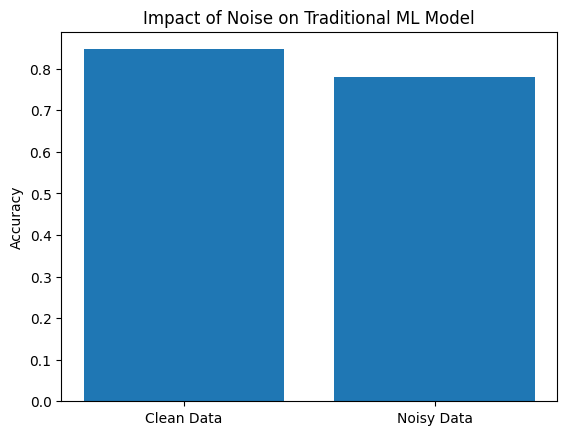

In [14]:
labels = ['Clean Data', 'Noisy Data']
accuracies = [clean_accuracy, noisy_accuracy]

plt.bar(labels, accuracies)
plt.title("Impact of Noise on Traditional ML Model")
plt.ylabel("Accuracy")
plt.show()